### KNN Classification on Social Network Ads Dataset

In [11]:
# Import the required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score,precision_score,recall_score

In [12]:
# Load the dataset
df = pd.read_csv("./datasets/assignment-05.csv")
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [13]:
# Explore the dataset

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
df.describe()

Dataset shape: (400, 5)

Column names:
Index(['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB

Missing values:
User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

Statistical summary:


,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [14]:
# Select features and target variable
X = df[['Age', 'EstimatedSalary']]
y = df['Purchased']

print("\nFeatures (X):")
display(X.head())

print("\nTarget variable (y):")
display(y.head())


Features (X):


,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000



Target variable (y):


0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64

In [15]:
# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(X,
 y, test_size=0.2, random_state=42,stratify=y)

print("\nTraining samples", len(X_train))
print("Testing samples:", len(X_test))


Training samples 320
Testing samples: 80


In [16]:
# Scale the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First five scaled training samples:")
print(X_train_scaled[:5])

First five scaled training samples:
[[-1.23446186 -0.367992  ]
 [-0.57764605 -1.05831408]
 [ 0.07916976  0.26480323]
 [ 1.95578636 -1.3747117 ]
 [ 0.36066225 -0.31046516]]


In [17]:
# Train the model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print("Actual values")
print(y_test.to_numpy())

print("\nPredicted values")
print(y_pred)

Actual values
[1 0 0 0 0 1 0 1 0 0 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 0 1 1 0 1 1 0 1 0 0 1 1
 0 0 1 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 0 1 0 0 0 1
 0 1 0 0 1 0]

Predicted values
[1 0 0 1 0 1 0 1 1 0 0 1 1 0 1 0 0 1 0 1 0 0 0 1 0 0 1 1 0 1 1 0 1 0 0 1 1
 1 0 1 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 0 0 1
 0 1 0 0 1 0]


Confusion Matrix:
[[47  4]
 [ 4 25]]


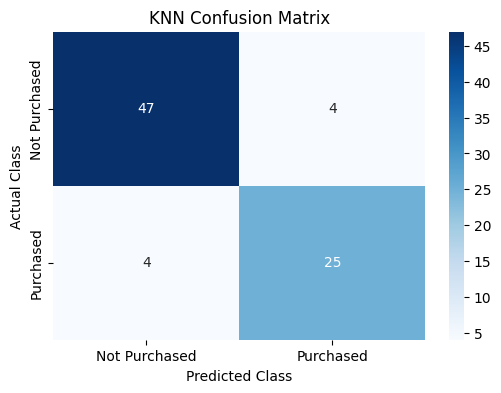

In [18]:
# Calculate the confusion matrix(cm)

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Purchased", "Purchased"],
    yticklabels=["Not Purchased", "Purchased"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("KNN Confusion Matrix")
plt.show()

In [19]:
# Calculate all required evaluation metrics

accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print(f"Accuracy   : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Error Rate : {error_rate:.4f} ({error_rate * 100:.2f}%)")
print(f"Precision  : {precision:.4f}")
print(f"Recall     : {recall:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Purchased", "Purchased"],
    zero_division=0
))

Accuracy   : 0.9000 (90.00%)
Error Rate : 0.1000 (10.00%)
Precision  : 0.8621
Recall     : 0.8621

Detailed Classification Report:
               precision    recall  f1-score   support

Not Purchased       0.92      0.92      0.92        51
    Purchased       0.86      0.86      0.86        29

     accuracy                           0.90        80
    macro avg       0.89      0.89      0.89        80
 weighted avg       0.90      0.90      0.90        80



    Actual  Predicted
0        1          1
1        0          0
2        0          0
3        0          1
4        0          0
5        1          1
6        0          0
7        1          1
8        0          1
9        0          0
10       0          0
11       1          1
12       1          1
13       0          0
14       1          1


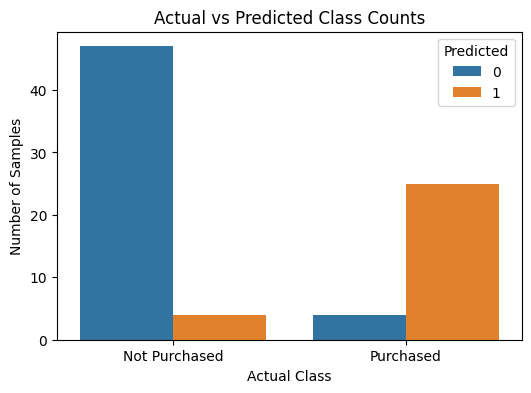

In [20]:
# Visualize the actual and predicted values
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

print(results.head(15))

plt.figure(figsize=(6, 4))
sns.countplot(data=results, x="Actual", hue="Predicted")

plt.xticks([0, 1], ["Not Purchased", "Purchased"])
plt.title("Actual vs Predicted Class Counts")
plt.xlabel("Actual Class")
plt.ylabel("Number of Samples")
plt.show()